In this Notebook, i will follow the steps and code suggestions represented by: Hands-On Machine Learning with Scikit-Learn and TensorFlow by Aurélien Géron (O'Reilly). Copyright 2017 Aurélien Géron 978-1-491-96229-9

Since i'm working on the Student Performance, i will re-use the same data, to follow the steps suggested in the book.

In [1]:
%store -r df
df


,school,age,Medu,reason,traveltime,studytime,failures,nursery,higher,internet,famrel,freetime,Dalc,Walc,health,absences,G1,G2,G3
0,GP,18,4,course,2,2,0,yes,yes,no,4,3,1,1,3,4,0,11,11
1,GP,17,1,course,1,2,0,no,yes,yes,5,3,1,1,3,2,9,11,11
2,GP,15,1,other,1,2,0,yes,yes,yes,4,3,2,3,3,6,12,13,12
3,GP,15,4,home,1,3,0,yes,yes,yes,3,2,1,1,5,0,14,14,14
4,GP,16,3,home,1,2,0,yes,yes,no,4,3,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,19,2,course,1,3,1,no,yes,yes,5,4,1,2,5,4,10,11,10
645,MS,18,3,course,1,2,0,yes,yes,yes,4,3,1,1,1,4,15,15,16
646,MS,18,1,course,2,2,0,yes,yes,no,1,1,1,1,5,6,11,12,9
647,MS,17,3,course,2,1,0,no,yes,yes,2,4,3,4,2,6,10,10,10


before steps ....

In [2]:
df.describe()

,age,Medu,traveltime,studytime,failures,famrel,freetime,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,1.568567,1.930663,0.221880,3.930663,3.180277,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,0.748660,0.829510,0.593235,0.955717,1.051093,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,2.000000,2.000000,0.000000,5.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


#### Chapter 2:End to End Machine learning Project

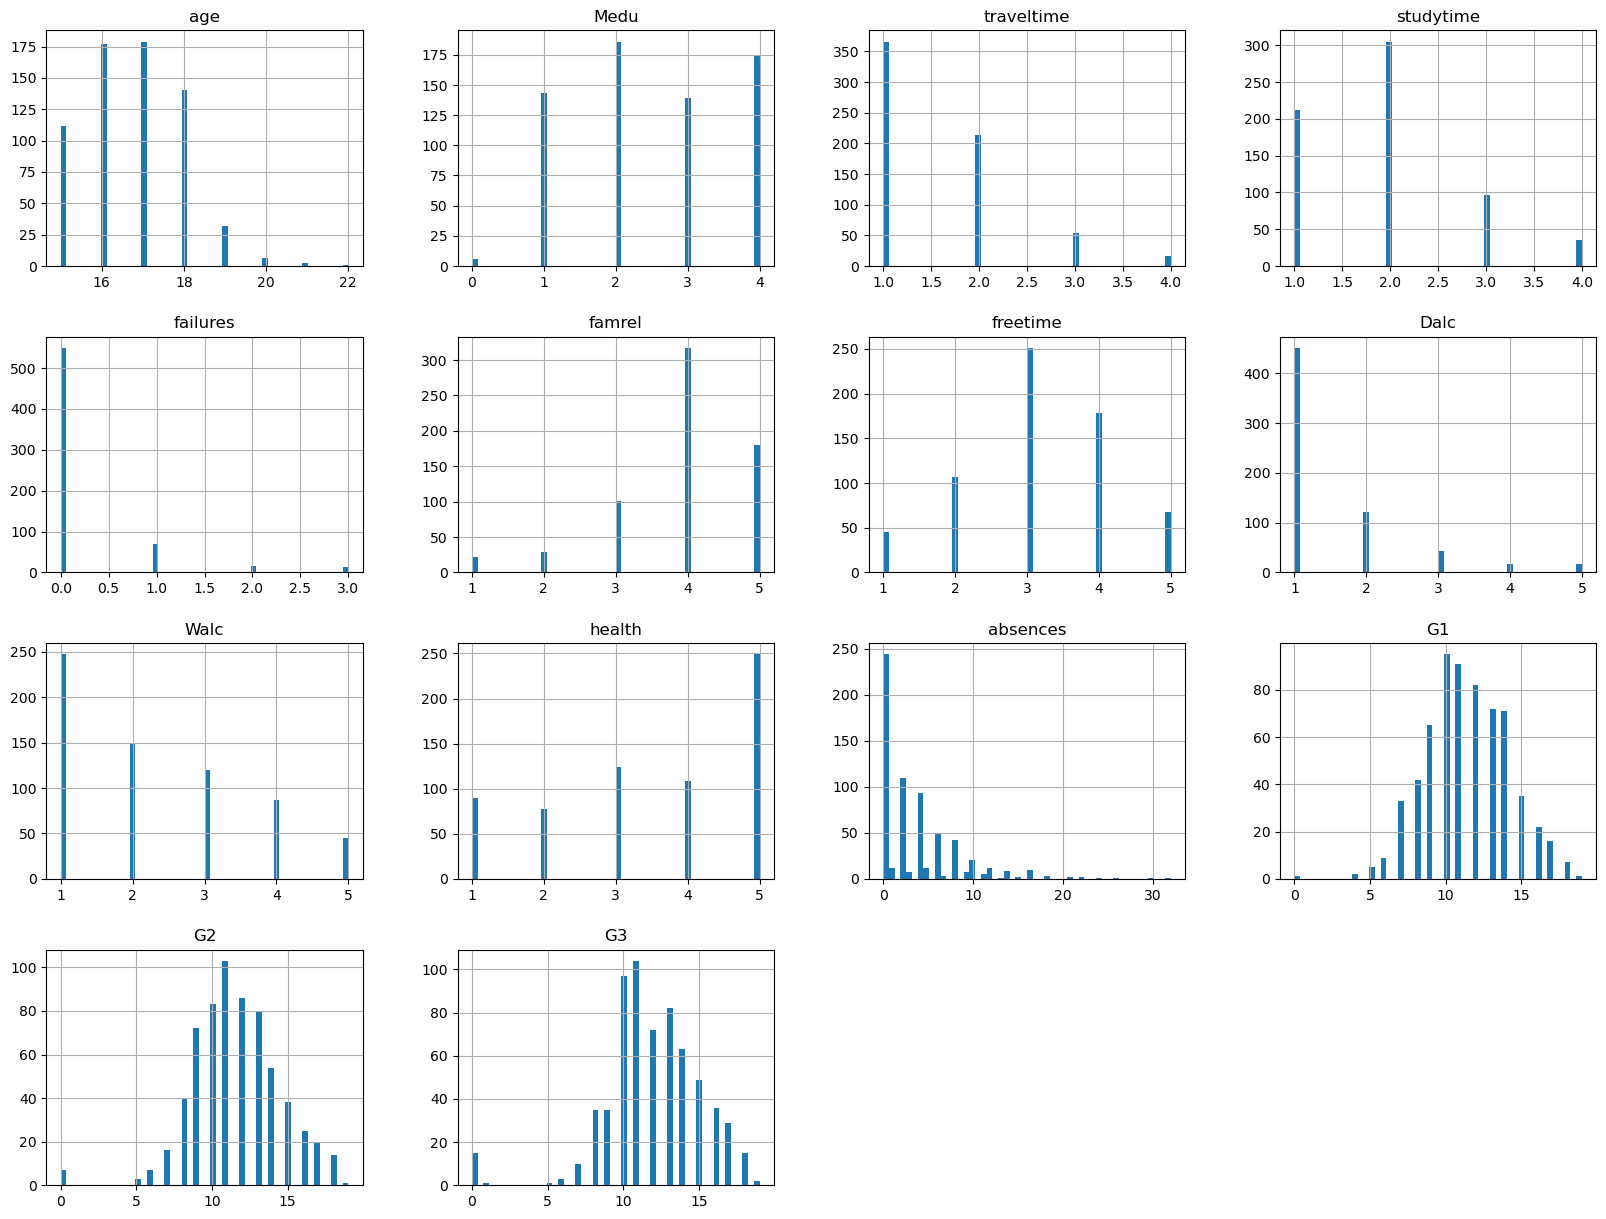

In [3]:
import matplotlib.pyplot as plt 

df.hist(bins = 50, figsize = (20,15))
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

In [5]:

corr_matrix = df.corr(numeric_only=True)

In [6]:
corr_matrix["G3"].sort_values(ascending=False)

G3            1.000000
G2            0.918548
G1            0.826387
studytime     0.249789
Medu          0.240151
famrel        0.063361
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime   -0.127173
Walc         -0.176619
Dalc         -0.204719
failures     -0.393316
Name: G3, dtype: float64

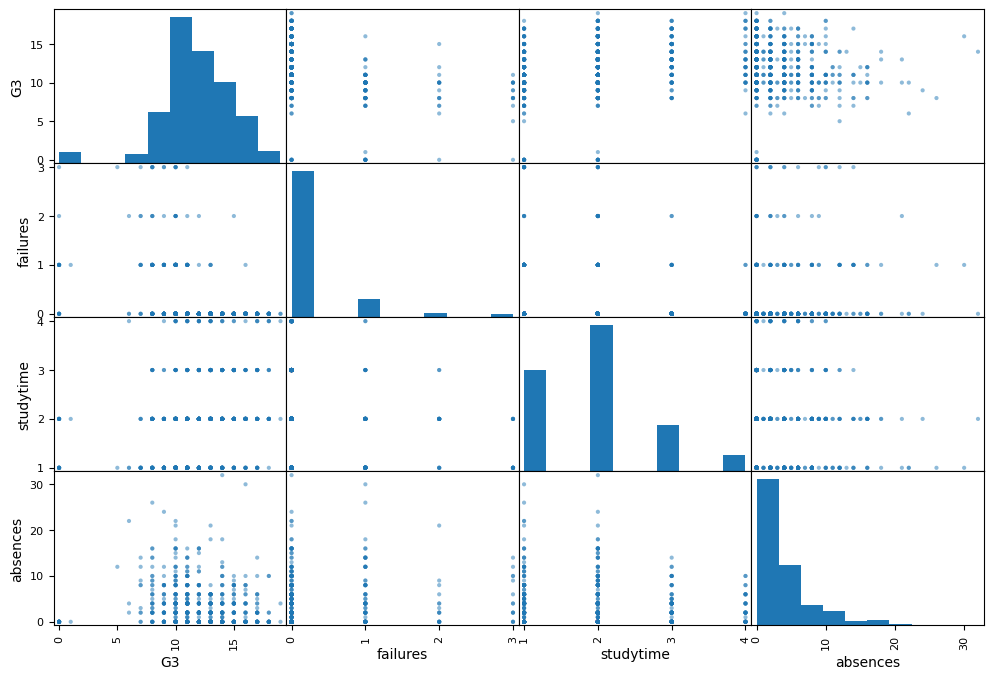

In [7]:
from pandas.plotting import scatter_matrix

attributes = ["G3", "failures", "studytime",
              "absences"]
scatter_matrix(df[attributes], figsize=(12, 8))
plt.show()

In [8]:
from sklearn.svm import SVR

In [9]:
X = df.drop(columns=["G3","G2", "G1"])
y = df["G3"]


In [10]:
import pandas as pd

X_encoded = pd.get_dummies(X, columns=['school', 'reason', 'nursery', 'higher', 'internet'])
X_encoded.head()

,age,Medu,traveltime,studytime,failures,famrel,freetime,Dalc,Walc,health,...,reason_course,reason_home,reason_other,reason_reputation,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes
0,18,4,2,2,0,4,3,1,1,3,...,True,False,False,False,False,True,False,True,True,False
1,17,1,1,2,0,5,3,1,1,3,...,True,False,False,False,True,False,False,True,False,True
2,15,1,1,2,0,4,3,2,3,3,...,False,False,True,False,False,True,False,True,False,True
3,15,4,1,3,0,3,2,1,1,5,...,False,True,False,False,False,True,False,True,False,True
4,16,3,1,2,0,4,3,1,2,5,...,False,True,False,False,False,True,False,True,True,False


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, random_state=0)


### Support vector Regressor

From what i understood, instead of scaling and then fitting a model, we can do both at the same time using scikitlearn pipeline.
And for the test set to be safe from being fitted to the model accedently.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

svr_pipeline = Pipeline([
    ('scaler', StandardScaler()),   
    ('model', SVR(kernel='rbf'))      
])

svr_pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0


In [13]:
svr_predictions = svr_pipeline.predict(X_test)

In [14]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
import numpy as np
train_preds = svr_pipeline.predict(X_train)
test_preds = svr_pipeline.predict(X_test)

train_rmse = np.sqrt(root_mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(root_mean_squared_error(y_test, test_preds))

print('Train SVR RMSE:', train_rmse)
print('Test SVR RMSE:', test_rmse)

Train SVR RMSE: 1.576626968768394
Test SVR RMSE: 1.62578302621833


fair! but needs optimization

In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np

param_grid = [
    {
        'model__kernel': ['rbf'], 
        'model__C': [1.0, 3.0, 10., 30., 100., 300., 1000.0],
        'model__gamma': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
    }
]

grid_search = GridSearchCV(
    svr_pipeline, 
    param_grid, 
    cv=3,
    scoring='neg_root_mean_squared_error'
)

grid_search.fit(X_train, y_train)

,estimator,"Pipeline(step...del', SVR())])"
,param_grid,"[{'model__C': [1.0, 3.0, ...], 'model__gamma': [0.01, 0.03, ...], 'model__kernel': ['rbf']}]"
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [16]:
grid_search.best_params_

{'model__C': 3.0, 'model__gamma': 0.01, 'model__kernel': 'rbf'}

In [17]:
final_svr_pipeline = grid_search.best_estimator_
final_svr_pipeline.fit(X_train, y_train)
preds = final_svr_pipeline.predict(X_test)

In [19]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
import numpy as np
train_preds = final_svr_pipeline.predict(X_train)
test_preds = final_svr_pipeline.predict(X_test)

train_rmse = np.sqrt(root_mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(root_mean_squared_error(y_test, test_preds))

print('Train SVR RMSE:', train_rmse)
print('Test SVR RMSE:', test_rmse)

Train SVR RMSE: 1.6092707075359043
Test SVR RMSE: 1.6277239705787154


The model indeed got optimized, but not really, the results remain almost the same

#### Classification

In this chapter i will use the SciKitlearn open dataset MNIST

In [21]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)

In [22]:
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [23]:
X, y = mnist["data"], mnist["target"]

In [24]:
X.shape


(70000, 784)

In [26]:
y.shape

(70000,)

In [27]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

In [29]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_train)


,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [30]:
from sklearn.model_selection import cross_val_score
cross_val_score(knn_clf, X_train, y_train, cv=5, scoring="accuracy")

array([0.96975   , 0.97016667, 0.96933333, 0.96816667, 0.969     ])

In [33]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

y_train_pred = cross_val_predict(knn_clf, X_train, y_train, cv=5)

cm = confusion_matrix(y_train, y_train_pred)
cm

array([[5883,    3,    5,    0,    1,    6,   16,    2,    2,    5],
       [   1, 6710,    8,    1,    2,    0,    3,   14,    1,    2],
       [  40,   60, 5713,   13,    8,    4,   10,   83,   18,    9],
       [   8,   15,   40, 5920,    1,   54,    3,   33,   34,   23],
       [   3,   52,    2,    1, 5639,    0,   14,   12,    1,  118],
       [  16,   13,    4,   75,    5, 5208,   64,    8,    5,   23],
       [  26,   13,    2,    0,    7,   21, 5848,    0,    1,    0],
       [   3,   68,   15,    2,   14,    1,    0, 6092,    3,   67],
       [  20,   72,   16,   85,   30,   95,   26,   18, 5429,   60],
       [  18,   11,    5,   40,   58,   11,    3,   78,   10, 5715]])

In [34]:
from scipy.ndimage import shift

In [35]:
def shift_image(image, dx, dy):
    image = image.reshape((28, 28))
    shifted_image = shift(image, [dy, dx], cval=0, mode="constant")
    return shifted_image.reshape([-1])

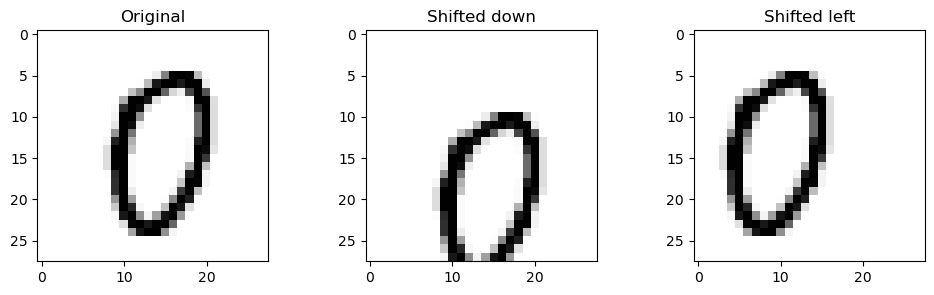

In [36]:
image = X_train[1000]  
shifted_image_down = shift_image(image, 0, 5)
shifted_image_left = shift_image(image, -5, 0)

plt.figure(figsize=(12, 3))
plt.subplot(131)
plt.title("Original")
plt.imshow(image.reshape(28, 28),
           interpolation="nearest", cmap="Greys")
plt.subplot(132)
plt.title("Shifted down")
plt.imshow(shifted_image_down.reshape(28, 28),
           interpolation="nearest", cmap="Greys")
plt.subplot(133)
plt.title("Shifted left")
plt.imshow(shifted_image_left.reshape(28, 28),
           interpolation="nearest", cmap="Greys")
plt.show()

In [37]:
X_train_augmented = [image for image in X_train]
y_train_augmented = [label for label in y_train]

for dx, dy in ((-1, 0), (1, 0), (0, 1), (0, -1)):
    for image, label in zip(X_train, y_train):
        X_train_augmented.append(shift_image(image, dx, dy))
        y_train_augmented.append(label)

X_train_augmented = np.array(X_train_augmented)
y_train_augmented = np.array(y_train_augmented)

In [38]:
shuffle_idx = np.random.permutation(len(X_train_augmented))
X_train_augmented = X_train_augmented[shuffle_idx]
y_train_augmented = y_train_augmented[shuffle_idx]

In [39]:
from sklearn.model_selection import GridSearchCV

param_grid = [{'weights': ["uniform", "distance"], 'n_neighbors': [3, 4, 5, 6]}]

knn_clf = KNeighborsClassifier()
grid_search = GridSearchCV(knn_clf, param_grid, cv=5)
grid_search.fit(X_train[:10_000], y_train[:10_000])
grid_search.best_params_

{'n_neighbors': 4, 'weights': 'distance'}

In [40]:
knn_clf = KNeighborsClassifier(**grid_search.best_params_)
knn_clf.fit(X_train_augmented, y_train_augmented)
augmented_accuracy = knn_clf.score(X_test, y_test)
augmented_accuracy

0.9763

The rest of classification tasks are already applied on Performance_prediction.ipynb notebook.

Chapter 6: SVMs 

Question 9: Train an SVM classifier on the MNIST dataset. Since SVM classifiers are binary
classifiers, you will need to use one-versus-all to classify all 10 digits. 

In [1]:
from sklearn.svm import SVC

In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)
X, y = mnist["data"], mnist["target"]
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

In [3]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(random_state=42))
])

param_grid = {
    'svc__kernel': ['rbf'],
    'svc__C': [1, 5, 10],
    'svc__gamma': ['scale', 0.001, 0.005, 0.01],
}

grid_search = GridSearchCV(
    pipe,
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

X_sub, y_sub = X_train[:2000], y_train[:2000]
grid_search.fit(X_sub, y_sub)

print("Best params:", grid_search.best_params_)
print("Best CV accuracy on subset:", grid_search.best_score_)

Best params: {'svc__C': 5, 'svc__gamma': 0.001, 'svc__kernel': 'rbf'}
Best CV accuracy on subset: 0.8800126963545254


In [4]:
from sklearn.metrics import accuracy_score

best_C = grid_search.best_params_['svc__C']
best_gamma = grid_search.best_params_['svc__gamma']

final_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', C=best_C, gamma=best_gamma, random_state=42))
])

final_pipe.fit(X_train, y_train)

y_test_pred = final_pipe.predict(X_test)
print("Final test accuracy:", accuracy_score(y_test, y_test_pred))

Final test accuracy: 0.973


This is chapter 7: Ensemble Methods

In [1]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)
X, y = mnist["data"], mnist["target"]

X_train, y_train = X[:50000], y[:50000]
X_val, y_val = X[50000:60000], y[50000:60000]
X_test, y_test = X[60000:], y[60000:]

In [2]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
et_clf = ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1)

rf_clf.fit(X_train, y_train)
et_clf.fit(X_train, y_train)

rf_val_pred = rf_clf.predict(X_val)
et_val_pred = et_clf.predict(X_val)

print('RF Validation Accuracy',accuracy_score(y_val, rf_val_pred))
print('ET Validation Accuracy', accuracy_score(y_val, et_val_pred))

RF Validation Accuracy 0.9736
ET Validation Accuracy 0.9743


In [3]:
from sklearn.ensemble import VotingClassifier

voting_clf = VotingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
        ("et", ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ],
    voting="soft",
    n_jobs=-1,
)

voting_clf.fit(X_train, y_train)
voting_val_pred = voting_clf.predict(X_val)

print('Voting Ensemble Validation Accuracy:', accuracy_score(y_val, voting_val_pred))

Voting Ensemble Validation Accuracy: 0.9749


In [4]:
voting_test_pred = voting_clf.predict(X_test)

print('RF Test Accuracy:',accuracy_score(y_test, rf_clf.predict(X_test)))
print('ET Test Accuracy:',accuracy_score(y_test, et_clf.predict(X_test)))
print('Voting Ensemble Test Accuracy:',accuracy_score(y_test, voting_test_pred))

RF Test Accuracy: 0.968
ET Test Accuracy: 0.9703
Voting Ensemble Test Accuracy: 0.9698


Combining the models indeed increases the accuracy, in this case not too impressive because i didn't fit an SVM and other models, it takes so long even when setting parameters to help things speed up!

In [5]:
import numpy as np

rf_val_pred = rf_clf.predict(X_val)
et_val_pred = et_clf.predict(X_val)
X_val_blender = np.column_stack([rf_val_pred, et_val_pred])
y_val_blender = y_val

In [6]:
blender = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
blender.fit(X_val_blender, y_val_blender)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [7]:
rf_test_pred = rf_clf.predict(X_test)
et_test_pred = et_clf.predict(X_test)

X_test_blender = np.column_stack([rf_test_pred, et_test_pred])
blender_test_pred = blender.predict(X_test_blender)

print('RF Test Accuracy:',accuracy_score(y_test, rf_test_pred))
print('ET Test Accuracy:',accuracy_score(y_test, et_test_pred))
print('Blender Test Accuracy:',accuracy_score(y_test, blender_test_pred))

RF Test Accuracy: 0.968
ET Test Accuracy: 0.9703
Blender Test Accuracy: 0.9693


In [8]:
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

pca = PCA(n_components=0.95, random_state=42)
X_train_reduced = pca.fit_transform(X_train)
X_test_reduced = pca.transform(X_test)

print(f"Reduced from {X_train.shape[1]} to {X_train_reduced.shape[1]} components")

Reduced from 784 to 154 components


In [9]:
X_val_reduced = pca.transform(X_val)

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_reduced, y_train)

rf_val_pred = rf_clf.predict(X_val_reduced)
print("RF Validation Accuracy:", accuracy_score(y_val, rf_val_pred))

RF Validation Accuracy: 0.952


In [10]:
X_test_reduced = pca.transform(X_test)
rf_test_pred = rf_clf.predict(X_test_reduced)
print("RF Test Accuracy:", accuracy_score(y_test, rf_test_pred))


RF Test Accuracy: 0.9461


With PCA, the RandomForest Model ran much faster with a stable validation and test accuracy scores.perfect!

In [1]:
pip install --upgrade pip

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 1.6 MB/s eta 0:00:01
   -------------------------- ------------- 1.3/2.0 MB 2.2 MB/s eta 0:00:01
   -------------------------------- ------- 1.6/2.0 MB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 1.9 MB/s  0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 25.3
    Uninstalling pip-25.3:
      Successfully uninstalled pip-25.3
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install tensorflow-cpu

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.8/351.2 MB 1.9 MB/s eta 0:03:10
   ---------------------------------------- 1.3/351.2 MB 2.2 MB/s eta 0:02:41
   ---------------------------------------- 1.8/351.2 MB 2.4 MB/s eta 0:02:29
   ---------------------------------------- 2.4/351.2 MB 2.2 MB/s eta 0:02:40
   ---------------------------------------- 2.9/351.2 MB 2.3 MB/s eta 0:02:31
   ---------------------------------------- 3.4/351.2 MB 2.3 MB/s eta 0:02:31
   ---------------------------------------- 3.7/351.2 MB 2.2 MB/s eta 0:02:39
   ---------------------------------------- 4.2/351.2 MB 2.2 MB/s eta 0:02:38
    --------------------------------------- 4.7/351.2 MB 2.3 MB/s eta 0:02:31
    ----------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [3]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("CPUs found:", tf.config.list_physical_devices("CPU"))
x = tf.random.normal([100, 100])
print("Tensor sum:", tf.reduce_sum(x).numpy())

TensorFlow version: 2.21.0
CPUs found: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Tensor sum: -117.76555


Intro to ANN: 

In [1]:
import tensorflow as tf
from tensorflow import keras

(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.mnist.load_data()

X_valid, X_train = X_train_full[:5000] / 255.0, X_train_full[5000:] / 255.0
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.0

print("Train:", X_train.shape, "Valid:", X_valid.shape, "Test:", X_test.shape)

Train: (55000, 28, 28) Valid: (5000, 28, 28) Test: (10000, 28, 28)


Build a Deep MLP

In [2]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 570,506 (2.18 MB)

 Trainable params: 568,970 (2.17 MB)

 Non-trainable params: 1,536 (6.00 KB)

Set Up the Callbacks (Checkpoints, Early Stopping, TensorBoard)

In [3]:
import datetime
from pathlib import Path

run_id = datetime.datetime.now().strftime("run_%Y%m%d_%H%M%S")
log_dir = Path("my_logs") / run_id
checkpoint_path = Path("best_mnist_mlp.keras")

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.TensorBoard(log_dir=log_dir)
]

Train on CPU and Evaluate on Test Data

In [5]:
%pip install tensorboard

   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.5 MB ? eta -:--:--
   --- ------------------------------------ 0.5/5.5 MB 361.3 kB/s eta 0:00:14
   --- ------------------------------------ 0.5/5.5 MB 361.3 kB/s eta 0:00:14
   ----- ---------------------------------- 0.8/5.5 MB 472.1 kB/s eta 0:00:11
   ----- ---------------------------------- 0.8/5.5 MB 472.1 kB/s eta 0:00:11
   ------- -------------------------------- 1.0/5.5 MB 511.6 kB/s e

In [4]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_data=(X_valid, y_valid),
    callbacks=callbacks
)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', test_acc)

Epoch 1/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9285 - loss: 0.2322
Epoch 1: val_accuracy improved from None to 0.96820, saving model to best_mnist_mlp.keras

Epoch 1: finished saving model to best_mnist_mlp.keras
430/430 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9285 - loss: 0.2322 - val_accuracy: 0.9682 - val_loss: 0.1091
Epoch 2/10
427/430 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9670 - loss: 0.1040
Epoch 2: val_accuracy improved from 0.96820 to 0.97640, saving model to best_mnist_mlp.keras

Epoch 2: finished saving model to best_mnist_mlp.keras
430/430 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9671 - loss: 0.1039 - val_accuracy: 0.9764 - val_loss: 0.0850
Epoch 3/10
428/430 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9751 - loss: 0.0776
Epoch 3: val_accuracy did not improve from 0.97640
430/430 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9751 - loss: 0.0774 - val_accuracy: 0.9748 - val_loss: 0.0860
Epoch 4/10
430/430 ━━━━━━━━━━━━━━━━━━━

View Learning Curves in TensorBoard

In [5]:
%load_ext tensorboard
%tensorboard --logdir my_logs

#### Deep Learning.


In [1]:
import tensorflow as tf
from tensorflow import keras

(X_train_full, y_train_full), (X_test_full, y_test_full) = keras.datasets.mnist.load_data()


train_mask = y_train_full < 5
test_mask = y_test_full < 5

X_04_full = X_train_full[train_mask] / 255.0
y_04_full = y_train_full[train_mask]

X_test_04 = X_test_full[test_mask] / 255.0
y_test_04 = y_test_full[test_mask]

X_valid_04, X_train_04 = X_04_full[:5000], X_04_full[5000:]
y_valid_04, y_train_04 = y_04_full[:5000], y_04_full[5000:]


In [2]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),

    # Hidden layer 1: 100 neurons, ELU activation, and He normal weight initialization
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),

    # Hidden layer 2: 100 neurons, ELU activation, and He normal weight initialization
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),

    # Hidden layer 3: 100 neurons, ELU activation, and He normal weight initialization
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),

    # Hidden layer 4: 100 neurons, ELU activation, and He normal weight initialization
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),

    # Hidden layer 5: 100 neurons, ELU activation, and He normal weight initialization
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),

    # Output layer: 5 neurons (one for each digit 0..4) with softmax probabilities
    keras.layers.Dense(5, activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           505 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 119,405 (466.43 KB)

 Trainable params: 119,405 (466.43 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
import datetime
from pathlib import Path

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"]
)
run_id = datetime.datetime.now().strftime("run_04_%Y%m%d_%H%M%S")
log_dir = Path("my_logs") / run_id
ckpt_dir = Path("checkpoints_04")
ckpt_dir.mkdir(parents=True, exist_ok=True)

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath=ckpt_dir / "ckpt_epoch_{epoch:02d}.keras",
    save_best_only=False,  
    save_freq="epoch", 
    verbose=0
)
early_stopping_cb = keras.callbacks.EarlyStopping(
    monitor="val_loss",          
    patience=5,                  
    restore_best_weights=True,   
    verbose=1
)
tensorboard_cb = keras.callbacks.TensorBoard(log_dir=log_dir)
history = model.fit(
    X_train_04, y_train_04,
    epochs=30,                                
    batch_size=128,                           
    validation_data=(X_valid_04, y_valid_04), 
    callbacks=[checkpoint_cb, early_stopping_cb, tensorboard_cb]
)
model.save("final_dnn_digits_0_to_4.keras")
test_loss, test_acc = model.evaluate(X_test_04, y_test_04, verbose=0)
print('Digits 0-4 Test Loss:', test_loss)
print('Digits 0-4 Test Accuracy:', test_acc)

Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9588 - loss: 0.1266 - val_accuracy: 0.9790 - val_loss: 0.0658
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9856 - loss: 0.0466 - val_accuracy: 0.9838 - val_loss: 0.0540
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9899 - loss: 0.0314 - val_accuracy: 0.9846 - val_loss: 0.0477
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9931 - loss: 0.0207 - val_accuracy: 0.9850 - val_loss: 0.0478
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9956 - loss: 0.0140 - val_accuracy: 0.9832 - val_loss: 0.0706
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9946 - loss: 0.0161 - val_accuracy: 0.9844 - val_loss: 0.0556
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9947 - loss: 0.0162 - val_accuracy: 0.9854 - val_loss: 0.0586
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9950 - loss: 0.0145 - val_accuracy: 0.

In [5]:
%pip install scikeras

Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
from keras import layers, models, optimizers
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import RandomizedSearchCV


def make_model(learning_rate=1e-3):
  net = models.Sequential(
      [layers.Input(shape=(28, 28)), layers.Flatten()] + [
          layers.Dense(100, activation="elu", kernel_initializer="he_normal")
          for _ in range(5)
      ] + [layers.Dense(5, activation="softmax")]
  )
  net.compile(
      optimizer=optimizers.Adam(learning_rate=learning_rate),
      loss="sparse_categorical_crossentropy",
      metrics=["accuracy"],
  )
  return net



clf = KerasClassifier(
    model=make_model, epochs=15, batch_size=128, verbose=0, random_state=42
)


search = RandomizedSearchCV(
    clf,
    param_distributions={
        "model__learning_rate": [3e-4, 1e-3, 3e-3],
        "batch_size": [64, 128, 256],
    },
    n_iter=4,
    cv=3,
    random_state=42,
)

search.fit(X_train_04, y_train_04)
print("Best params:", search.best_params_, "CV acc:", search.best_score_)
print("Test acc:", search.score(X_test_04, y_test_04))

Best params: {'model__learning_rate': 0.001, 'batch_size': 64} CV acc: 0.9853102047194874
Test acc: 0.9902704806382565


Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9626 - loss: 0.1167 - val_accuracy: 0.9762 - val_loss: 0.0783
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9866 - loss: 0.0457 - val_accuracy: 0.9742 - val_loss: 0.0873
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9922 - loss: 0.0279 - val_accuracy: 0.9748 - val_loss: 0.0839
Epoch 4/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9936 - loss: 0.0200 - val_accuracy: 0.9764 - val_loss: 0.0740
Epoch 5/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9938 - loss: 0.0180 - val_accuracy: 0.9838 - val_loss: 0.0519
Epoch 6/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9964 - loss: 0.0112 - val_accuracy: 0.9744 - val_loss: 0.0920
Epoch 7/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9962 - loss: 0.0109 - val_accuracy: 0.9832 - val_loss: 0.0493
Epoch 8/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9964 - loss: 0.0106 - val_accuracy: 0.

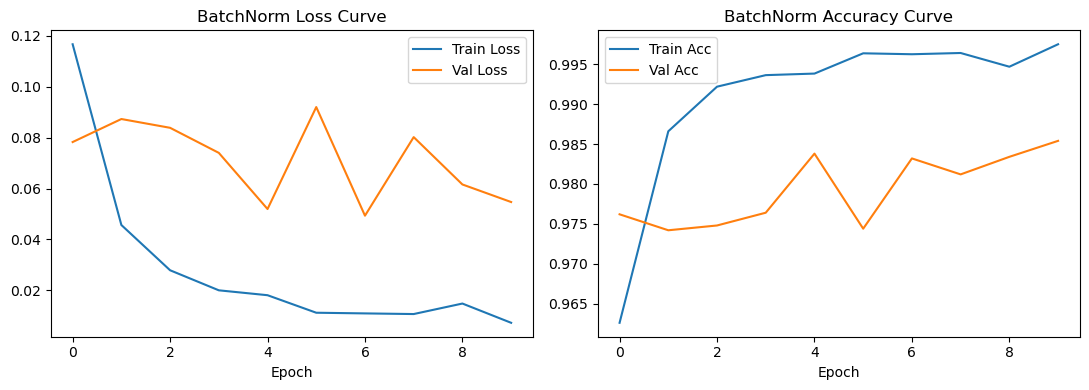

In [5]:
import datetime
from pathlib import Path
import matplotlib.pyplot as plt

keras.utils.set_random_seed(42)
bn_model = keras.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
])

for _ in range(5):
    bn_model.add(keras.layers.Dense(100, use_bias=False, kernel_initializer="he_normal"))
    bn_model.add(keras.layers.BatchNormalization())
    bn_model.add(keras.layers.Activation("elu"))

bn_model.add(keras.layers.Dense(5, activation="softmax"))

bn_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"]
)

run_id = datetime.datetime.now().strftime("bn_04_%Y%m%d_%H%M%S")
bn_tb_cb = keras.callbacks.TensorBoard(log_dir=Path("my_logs") / run_id)
bn_es_cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)

bn_history = bn_model.fit(
    X_train_04, y_train_04,
    epochs=10,
    batch_size=64,
    validation_data=(X_valid_04, y_valid_04),
    callbacks=[bn_es_cb, bn_tb_cb]
)

bn_test_loss, bn_test_acc = bn_model.evaluate(X_test_04, y_test_04, verbose=0)
print('BatchNorm Test Loss:', bn_test_loss, 'Test Accuracy:', bn_test_acc)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(bn_history.history["loss"], label="Train Loss")
ax1.plot(bn_history.history["val_loss"], label="Val Loss")
ax1.set_title("BatchNorm Loss Curve")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(bn_history.history["accuracy"], label="Train Acc")
ax2.plot(bn_history.history["val_accuracy"], label="Val Acc")
ax2.set_title("BatchNorm Accuracy Curve")
ax2.set_xlabel("Epoch")
ax2.legend()

plt.tight_layout()
plt.show()

Epoch 1/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9278 - loss: 0.2360 - val_accuracy: 0.9702 - val_loss: 0.0981
Epoch 2/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9654 - loss: 0.1176 - val_accuracy: 0.9784 - val_loss: 0.0700
Epoch 3/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9721 - loss: 0.0937 - val_accuracy: 0.9800 - val_loss: 0.0701
Epoch 4/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9773 - loss: 0.0754 - val_accuracy: 0.9818 - val_loss: 0.0642
Epoch 5/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9803 - loss: 0.0655 - val_accuracy: 0.9834 - val_loss: 0.0594
Epoch 6/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9820 - loss: 0.0613 - val_accuracy: 0.9828 - val_loss: 0.0549
Epoch 7/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9844 - loss: 0.0514 - val_accuracy: 0.9826 - val_loss: 0.0650
Epoch 8/15
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9849 - loss: 0.0477 - val_accuracy: 0.

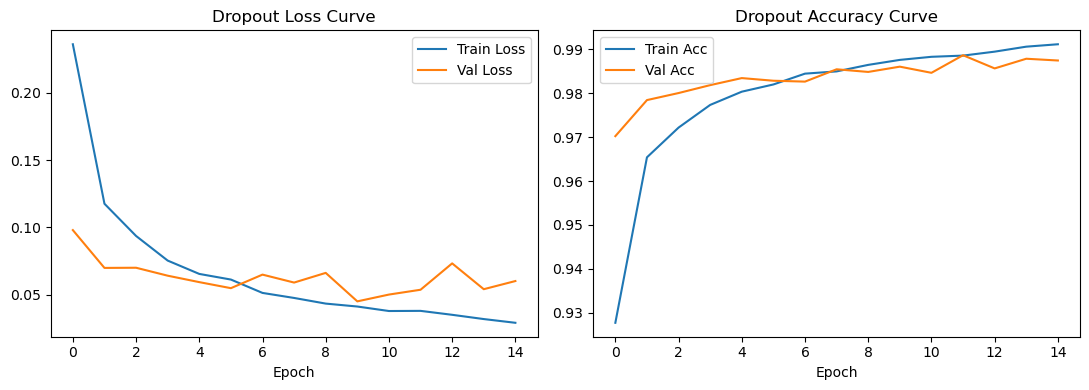

In [7]:
keras.utils.set_random_seed(42)

drop_model = keras.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
])

for _ in range(5):
    drop_model.add(keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"))
    drop_model.add(keras.layers.Dropout(rate=0.2))  

drop_model.add(keras.layers.Dense(5, activation="softmax"))
drop_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"]
)


run_id = datetime.datetime.now().strftime("drop_04_%Y%m%d_%H%M%S")
drop_tb_cb = keras.callbacks.TensorBoard(log_dir=Path("my_logs") / run_id)
drop_es_cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)


drop_history = drop_model.fit(
    X_train_04, y_train_04,
    epochs=15,
    batch_size=64,
    validation_data=(X_valid_04, y_valid_04),
    callbacks=[drop_es_cb, drop_tb_cb]
)


drop_test_loss, drop_test_acc = drop_model.evaluate(X_test_04, y_test_04, verbose=0)
print('Dropout Test Loss:', drop_test_loss, 'Test Accuracy:', drop_test_acc)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(drop_history.history["loss"], label="Train Loss")
ax1.plot(drop_history.history["val_loss"], label="Val Loss")
ax1.set_title("Dropout Loss Curve")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(drop_history.history["accuracy"], label="Train Acc")
ax2.plot(drop_history.history["val_accuracy"], label="Val Acc")
ax2.set_title("Dropout Accuracy Curve")
ax2.set_xlabel("Epoch")
ax2.legend()

plt.tight_layout()
plt.show()

Dropout helped enough.

Test loss improved: At 0.0259, it's lower than the earlier BatchNorm run and slightly below your initial 0.0302 baseline, while keeping test accuracy right around 99.01%.

Overfitting stayed controlled: Because EarlyStopping restored Epoch 10's weights, the network didn't drift into heavy memorization in later epochs.

#### Transfer learning.


In [8]:

(X_train_full, y_train_full), (X_test_full, y_test_full) = keras.datasets.mnist.load_data()

train_59_mask = y_train_full >= 5
test_59_mask = y_test_full >= 5

X_59_all = X_train_full[train_59_mask] / 255.0
y_59_all = y_train_full[train_59_mask] - 5

X_test_59 = X_test_full[test_59_mask] / 255.0
y_test_59 = y_test_full[test_59_mask] - 5


rng = np.random.default_rng(42)
few_shot_indices = []
for digit in range(5):
    digit_idx = np.flatnonzero(y_59_all == digit)
    chosen = rng.choice(digit_idx, size=100, replace=False)
    few_shot_indices.append(chosen)

few_shot_idx = np.concatenate(few_shot_indices)
rng.shuffle(few_shot_idx)

X_train_59_small = X_59_all[few_shot_idx]
y_train_59_small = y_59_all[few_shot_idx]


remaining_mask = np.ones(len(y_59_all), dtype=bool)
remaining_mask[few_shot_idx] = False
X_valid_59 = X_59_all[remaining_mask][:2500]
y_valid_59 = y_59_all[remaining_mask][:2500]


In [9]:
import time
keras.utils.set_random_seed(42)

base_model = keras.models.load_model("final_dnn_digits_0_to_4.keras")
reused_layers = base_model.layers[1:-1] if isinstance(base_model.layers[0], keras.layers.InputLayer) else base_model.layers[:-1]


for layer in reused_layers:
    layer.trainable = False

tl_model = keras.Sequential(
    [keras.layers.Input(shape=[28, 28])]
    + reused_layers
    + [keras.layers.Dense(5, activation="softmax")]
)

tl_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"]
)


t0 = time.perf_counter()
tl_history = tl_model.fit(
    X_train_59_small, y_train_59_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_valid_59, y_valid_59),
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0)],
    verbose=0
)
elapsed_b = time.perf_counter() - t0

test_loss_b, test_acc_b = tl_model.evaluate(X_test_59, y_test_59, verbose=0)
print('Test Loss:', test_loss_b, 'Test Acc:', test_acc_b)

Test Loss: 0.5498570799827576 Test Acc: 0.8179386854171753


In [10]:

frozen_extractor = keras.Sequential(
    [keras.layers.Input(shape=[28, 28])] + reused_layers
)

cached_train_59 = frozen_extractor.predict(X_train_59_small, verbose=0)
cached_valid_59 = frozen_extractor.predict(X_valid_59, verbose=0)
cached_test_59 = frozen_extractor.predict(X_test_59, verbose=0)

keras.utils.set_random_seed(42)
cached_clf = keras.Sequential([
    keras.layers.Input(shape=cached_train_59.shape[1:]),
    keras.layers.Dense(5, activation="softmax")
])

cached_clf.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"]
)

t0 = time.perf_counter()
cached_clf.fit(
    cached_train_59, y_train_59_small,
    epochs=30,
    batch_size=32,
    validation_data=(cached_valid_59, y_valid_59),
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0)],
    verbose=0
)
elapsed_c = time.perf_counter() - t0

test_loss_c, test_acc_c = cached_clf.evaluate(cached_test_59, y_test_59, verbose=0)
print('Test Loss',test_loss_c,'Test Accuracy:', test_acc_c)

Test Loss 0.5505251884460449 Test Accuracy: 0.8257560133934021


run is much faster

In [11]:
keras.utils.set_random_seed(42)


base_model_d = keras.models.load_model("final_dnn_digits_0_to_4.keras")
all_hidden_d = [l for l in base_model_d.layers if isinstance(l, keras.layers.Dense)][:-1]

four_hidden_layers = all_hidden_d[:4]
for layer in four_hidden_layers:
    layer.trainable = False

tl_4_model = keras.Sequential(
    [keras.layers.Input(shape=[28, 28]), keras.layers.Flatten()]+ four_hidden_layers + [keras.layers.Dense(5, activation="softmax")]
)

tl_4_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"]
)

tl_4_model.fit(
    X_train_59_small, y_train_59_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_valid_59, y_valid_59),
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0)],
    verbose=0
)

test_loss_d, test_acc_d = tl_4_model.evaluate(X_test_59, y_test_59, verbose=0)
print('Test Loss:', test_loss_d , 'Test Acc:', test_acc_d)

Test Loss: 0.5010759830474854 Test Acc: 0.8438593149185181


In [12]:

for layer in tl_model.layers[-3:-1]:  
    layer.trainable = True

tl_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    metrics=["accuracy"]
)

tl_model.fit(
    X_train_59_small, y_train_59_small,
    epochs=30,
    batch_size=32,
    validation_data=(X_valid_59, y_valid_59),
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0)],
    verbose=0
)

test_loss_e, test_acc_e = tl_model.evaluate(X_test_59, y_test_59, verbose=0)
print('Test Loss:', test_loss_e, 'Test Acc:', test_acc_e)

Test Loss: 0.37486204504966736 Test Acc: 0.8827401995658875


#### Pretraining on an auxiliary task.

In [13]:
keras.utils.set_random_seed(42)


def make_five_layer_trunk(name_prefix):
  layers_list = [
      keras.layers.Dense(
          100,
          activation="elu",
          kernel_initializer="he_normal",
          name=f"{name_prefix}_dense_{i + 1}",
      )
      for i in range(5)
  ]
  return keras.Sequential(layers_list, name=name_prefix)



input_a = keras.layers.Input(shape=[28, 28], name="image_a")
input_b = keras.layers.Input(shape=[28, 28], name="image_b")


flatten = keras.layers.Flatten(name="flatten")
flat_a = flatten(input_a)
flat_b = flatten(input_b)


dnn_a = make_five_layer_trunk("dnn_a")
dnn_b = make_five_layer_trunk("dnn_b")


feat_a = dnn_a(flat_a)
feat_b = dnn_b(flat_b)


merged = keras.layers.Concatenate(name="concat_features")([feat_a, feat_b])


hidden_10 = keras.layers.Dense(
    10, activation="elu", kernel_initializer="he_normal", name="comparison_10"
)(merged)

output = keras.layers.Dense(1, activation="sigmoid", name="same_or_diff")(
    hidden_10
)

pair_model = keras.Model(
    inputs=[input_a, input_b], outputs=output, name="auxiliary_pair_model"
)
pair_model.summary()

Model: "auxiliary_pair_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_a             │ (None, 28, 28)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_b             │ (None, 28, 28)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 784)       │          0 │ image_a[0][0],    │
│                     │                   │            │ image_b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dnn_a (Sequential)  │ (None, 100)       │    118,900 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dnn_b (Sequential)  │ (None, 100)       │    118,900 │ flatten[1][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_features     │ (None, 200)       │          0 │ dnn_a[0][0],      │
│ (Concatenate)       │                   │            │ dnn_b[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ comparison_10       │ (None, 10)        │      2,010 │ concat_features[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ same_or_diff        │ (None, 1)         │         11 │ comparison_10[0]… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 239,821 (936.80 KB)

 Trainable params: 239,821 (936.80 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
(X_train_all, y_train_all), (X_test, y_test) = keras.datasets.mnist.load_data()
X_train_all = X_train_all.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0


rng = np.random.default_rng(42)
perm = rng.permutation(len(X_train_all))
X_shuf, y_shuf = X_train_all[perm], y_train_all[perm]

X_split1, y_split1 = X_shuf[:55000], y_shuf[:55000]  
X_split2, y_split2 = X_shuf[55000:], y_shuf[55000:]  

indices_by_digit = [np.flatnonzero(y_split1 == d) for d in range(10)]


def generate_pair_batch(X, y, indices_by_class, batch_size=128):
  half = batch_size // 2
  other_half = batch_size - half

  imgs_a = np.empty((batch_size, 28, 28), dtype=np.float32)
  imgs_b = np.empty((batch_size, 28, 28), dtype=np.float32)
  labels = np.empty((batch_size, 1), dtype=np.float32)

  
  for i in range(half):
    digit = rng.integers(0, 10)
    idx_a, idx_b = rng.choice(indices_by_class[digit], size=2, replace=False)
    imgs_a[i] = X[idx_a]
    imgs_b[i] = X[idx_b]
    labels[i, 0] = 0.0

  
  for i in range(half, batch_size):
    d1, d2 = rng.choice(10, size=2, replace=False)
    idx_a = rng.choice(indices_by_class[d1])
    idx_b = rng.choice(indices_by_class[d2])
    imgs_a[i] = X[idx_a]
    imgs_b[i] = X[idx_b]
    labels[i, 0] = 1.0

 
  order = rng.permutation(batch_size)
  return (imgs_a[order], imgs_b[order]), labels[order]



(sample_a, sample_b), sample_y = generate_pair_batch(X_split1, y_split1, indices_by_digit, batch_size=8)
print("Batch shapes:", sample_a.shape, sample_b.shape, sample_y.shape)
print("Labels (0=same, 1=diff):", sample_y.ravel())

Batch shapes: (8, 28, 28) (8, 28, 28) (8, 1)
Labels (0=same, 1=diff): [1. 0. 0. 1. 0. 0. 1. 1.]


In [15]:

pair_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

def pair_batch_generator(X, y, indices_by_class, batch_size=128):
  while True:
    yield generate_pair_batch(X, y, indices_by_class, batch_size=batch_size)


val_indices_by_digit = [np.flatnonzero(y_split1 == d) for d in range(10)]
(X_val_a, X_val_b), y_val_pairs = generate_pair_batch(
    X_split1, y_split1, val_indices_by_digit, batch_size=2000
)

steps_per_epoch = 400

aux_history = pair_model.fit(
    pair_batch_generator(X_split1, y_split1, indices_by_digit, batch_size=128),
    steps_per_epoch=steps_per_epoch,
    epochs=10,
    validation_data=((X_val_a, X_val_b), y_val_pairs),
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
        )
    ],
)

Epoch 1/10


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


400/400 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.7955 - loss: 0.4319 - val_accuracy: 0.8735 - val_loss: 0.3063
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8911 - loss: 0.2670 - val_accuracy: 0.8985 - val_loss: 0.2432
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9170 - loss: 0.2095 - val_accuracy: 0.9285 - val_loss: 0.1722
Epoch 4/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9380 - loss: 0.1654 - val_accuracy: 0.9510 - val_loss: 0.1345
Epoch 5/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9491 - loss: 0.1407 - val_accuracy: 0.9510 - val_loss: 0.1324
Epoch 6/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9581 - loss: 0.1179 - val_accuracy: 0.9590 - val_loss: 0.1064
Epoch 7/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9625 - loss: 0.1076 - val_accuracy: 0.9635 - val_loss: 0.1041
Epoch 8/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9680 - loss: 0.0928 - val_accuracy: 0.96

In [16]:
keras.utils.set_random_seed(42)

dnn_a.trainable = False
for layer in dnn_a.layers:
  layer.trainable = False

aux_clf_model = keras.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    dnn_a,
    keras.layers.Dense(10, activation="softmax"),
])

aux_clf_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"],
)

X_tr2, y_tr2 = X_split2[:4000], y_split2[:4000]
X_va2, y_va2 = X_split2[4000:], y_split2[4000:]

clf_history = aux_clf_model.fit(
    X_tr2,
    y_tr2,
    epochs=30,
    batch_size=64,
    validation_data=(X_va2, y_va2),
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
        )
    ],
)

test_loss_10, test_acc_10 = aux_clf_model.evaluate(X_test, y_test, verbose=0)
print('Auxiliary Pretrained 10-Class Test Loss:', test_loss_10 ,'Test Acc:',test_acc_10)

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5587 - loss: 2.6714 - val_accuracy: 0.9160 - val_loss: 0.3439
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9413 - loss: 0.2158 - val_accuracy: 0.9440 - val_loss: 0.2332
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9525 - loss: 0.1705 - val_accuracy: 0.9520 - val_loss: 0.2075
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9585 - loss: 0.1534 - val_accuracy: 0.9540 - val_loss: 0.1919
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9607 - loss: 0.1430 - val_accuracy: 0.9570 - val_loss: 0.1810
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9635 - loss: 0.1357 - val_accuracy: 0.9570 - val_loss: 0.1729
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9647 - loss: 0.1301 - val_accuracy: 0.9590 - val_loss: 0.1667
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9647 - loss: 0.1257 - val_accuracy: 0.9600 - val_loss: